# 23 · 拍卖、支付规则与出价

第18章保留总览；本章单独深入一个问题。正式200k实验不覆盖，教学训练使用独立共享记录。

## 先预测：赢家报价就是实际花费吗？

本章全部是独立模拟市场，不使用Criteo估计反事实收益。每曝光报价b=p_hat×虚构点击价值×倍数，单位为每曝光货币，既不是CPC也不是eCPM。二价规则使赢家支付次高合格报价和外部报价的最大值。

先用单请求手算：两广告主估计点击率.5/.3，点击价值都为2，报价1/.6，外部价.2。谁赢，付多少？有预算时“诚实出价最优”的简化结论还能直接套吗？

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from reclab.ads import latest, load_data, split_groups, NUM, CAT, FEATURES
from reclab.paths import ARTIFACTS
from reclab.probability import evaluate
preview=ARTIFACTS/'notebook-previews';preview.mkdir(parents=True,exist_ok=True)
from reclab.auction import simulate,market
one={'estimate':np.array([[.5,.3]]),'true_p':np.array([[.4,.2]]),'value':np.array([2.,2.]),'clicks':np.array([[True,False]]),'external':np.array([.2])}
print('Inputs:',one['estimate'].shape,'bid:',one['estimate']*one['value'])
answer=simulate(one,budget=2.)
assert np.isclose(answer['spend'],.6) and answer['wins']==1
print({k:answer[k] for k in ['spend','expected_click_value','realized_click_value','expected_advertiser_surplus']})

Inputs: (1, 2) bid: [[1.  0.6]]
{'spend': 0.6, 'expected_click_value': 0.8, 'realized_click_value': 2.0, 'expected_advertiser_surplus': 0.20000000000000007}


## 只改一个变量：外部竞争价

保持内部报价、点击潜在结果和预算不变，把外部报价升到1.1。内部最高报价1不再能赢，本系统无成交、无支付；外部广告如何成交不在模型中。这条边界防止把所有请求都当成内部广告曝光。

二价支付不超过获胜bid，但仍需预算约束。当前实现保守地要求完整bid可负担才参拍，而不是在看到成交价之后才决定是否有钱；这种规则可能损失可买的请求，属于明确的模型假设。

In [2]:
external_changed={**one,'external':np.array([1.1])}
no_sale=simulate(external_changed,budget=2.)
assert no_sale['wins']==0 and no_sale['spend']==0
print('External price changed only: wins',no_sale['wins'],'spend',no_sale['spend'])
small_budget=simulate(one,budget=.7)
print('Budget .7 excludes bid1 even though hypothetical second price .6 would be affordable:',small_budget['advertisers'])

External price changed only: wins 0 spend 0.0
Budget .7 excludes bid1 even though hypothetical second price .6 would be affordable: [{'spend': 0.0, 'wins': 0, 'clicks': 0}, {'spend': 0.2, 'wins': 1, 'clicks': 0}]


## 真正运行：固定潜在市场，只改变出价倍数

6000次请求、3广告主；true_p为构造Beta概率，估计概率带乘性噪声，潜在点击矩阵一次生成。所有策略共享同一个市场，所以差异不来自重新抽取点击。后半程价值更高是预先构造的假设。

本格固定预算60及pacing，仅改变倍数.25/.5/1/2。它是敏感性实验，不是寻找线上最优出价；所有内部广告主同时改变策略，外部报价保持不变，不能假设现实竞争者也会如此。

In [3]:
synthetic=market(seed=42)
print('Estimated/true probabilities:',synthetic['estimate'].shape,'potential clicks:',synthetic['clicks'].shape)
rows=[]
for multiplier in [.25,.5,1.,2.]:
 r=simulate(synthetic,multiplier=multiplier,paced=True)
 rows.append({'multiplier':multiplier,**{k:r[k] for k in ['spend','wins','clicks','expected_click_value','expected_advertiser_surplus','budget_ok']}})
table=pd.DataFrame(rows);display(table)
assert table.budget_ok.all()

Estimated/true probabilities: (6000, 3) potential clicks: (6000, 3)


,multiplier,spend,wins,clicks,expected_click_value,expected_advertiser_surplus,budget_ok
0,0.25,179.795277,2822,498,981.983513,802.188236,True
1,0.50,179.667495,2744,297,594.607116,414.939622,True
2,1.00,179.352946,2522,181,363.687988,184.335042,True
3,2.00,178.952032,2281,109,233.588903,54.636870,True


## 解释：收入、价值、盈余不是同一个目标

平台模拟收入等于支付之和；广告主期望点击价值使用构造true_p×点击价值；期望盈余=价值−支付；实际点击价值还包含Bernoulli波动。平台收入近似用满预算时，广告主可能赢得完全不同的曝光。

因此只看花费曲线很难解释策略好坏。下面同时画模拟花费与期望点击价值，明确是模拟货币。不要把这里的高价值当作真实ROI，也没有转换、利润或延迟归因。

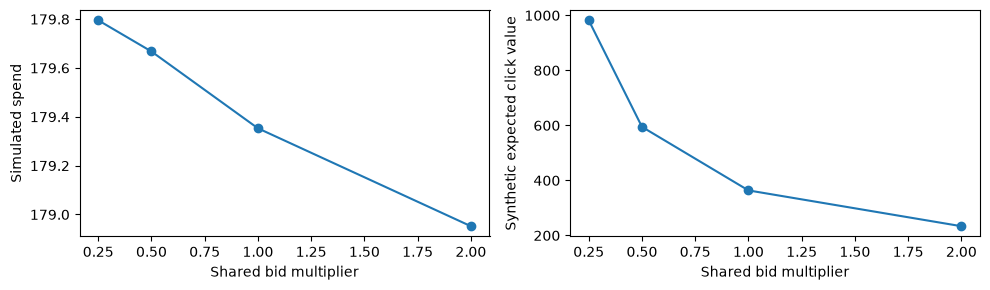

No causal or revenue claim is inferred from public click logs.


In [4]:
fig,axes=plt.subplots(1,2,figsize=(10,3));axes[0].plot(table.multiplier,table.spend,'o-');axes[1].plot(table.multiplier,table.expected_click_value,'o-')
axes[0].set(xlabel='Shared bid multiplier',ylabel='Simulated spend');axes[1].set(xlabel='Shared bid multiplier',ylabel='Synthetic expected click value')
fig.tight_layout();fig.savefig(preview/'23_bids.png',dpi=130);plt.show()
print('No causal or revenue claim is inferred from public click logs.')

## 练习：固定一个策略，检查随机性

只改变seed，保持倍数1、预算60和pacing。相同种子下的策略对照是配对的，跨种子的值则反映有限模拟市场的波动。三种子不足以证明稳定工业收益。

解释要求：分别写出支付规则、不成交规则、预算资格、true_p与estimate的角色；说明为什么预测概率校准更好也不能自动推出某种拍卖政策收益更好。

In [5]:
display(pd.DataFrame([{'seed':seed,**{k:r[k] for k in ['spend','expected_click_value','realized_click_value','budget_ok']}} for seed in [41,42,43] for r in [simulate(market(seed),paced=True)]]))
print('Real prediction probabilities and synthetic auction outcomes remain separate evidence layers.')

,seed,spend,expected_click_value,realized_click_value,budget_ok
0,41,179.523495,362.738625,359.0,True
1,42,179.352946,363.687988,359.5,True
2,43,179.534714,362.467222,368.0,True


Real prediction probabilities and synthetic auction outcomes remain separate evidence layers.
